# مشروع التنبؤ بوقت توصيل طلبات الطعام

## 1. فهم المشكلة

 1.1 تحديد الهدف من المشروع (Target)   

الهدف الأساسي من المشروع هو التنبؤ بوقت توصيل طلب الطعام بالدقائق.

- **اسم العمود المستهدف:** `Time_taken(min)`
- **نوع المشكلة:** تعلم آلي خاضع للإشراف (Supervised Learning).
- **نوع التنبؤ:** انحدار (Regression)، لأننا نتوقع قيمة رقمية تمثل عدد دقائق التوصيل.

 1.2 المستخدمون المستهدفون

يوجد نوعان من المستخدمين:

1. **العميل:** يحتاج إلى معرفة الوقت المتوقع لوصول طلبه حتى يستطيع تنظيم وقته.
2. **مدير العمليات:** يحتاج إلى متابعة أوقات التوصيل ومعرفة العوامل التي تسبب التأخير، حتى يتمكن من تحسين أداء التوصيل.

عند فتح المنتج، يجب أن تظهر للعميل مدة التوصيل المتوقعة بالدقائق، بينما تظهر للمدير لوحة تحكم توضح أوقات التوصيل والعوامل المرتبطة بالتأخير.

### 1.3 الأسئلة التي سيجيب عنها المشروع

1. ما العوامل الأكثر تأثيرًا في وقت توصيل طلبات الطعام؟
2. هل تؤثر حركة المرور والطقس والمسافة في زيادة وقت التوصيل؟
3. هل يمكن بناء نموذج ذكاء اصطناعي يتوقع وقت التوصيل بدقة ويساعد على إعطاء العميل وقتًا متوقعًا أقرب للواقع؟

## 2. أول نظرة على البيانات

In [1]:
import pandas as pd

df = pd.read_csv("data/raw.csv")

df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [2]:
print("حجم البيانات:", df.shape)

print("\nعدد القيم المفقودة:")
print(df.isnull().sum().sum())

print("\nعدد الأعمدة:")
print(len(df.columns))

حجم البيانات: (45593, 20)

عدد القيم المفقودة:
0

عدد الأعمدة:
20


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [4]:
print("عدد الصفوف المكررة:", df.duplicated().sum())

عدد الصفوف المكررة: 0


In [5]:
df.describe()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition
count,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000
mean,17.017729,70.231332,17.465186,70.845702,1.023359
std,8.185109,22.883647,7.335122,21.118812,0.839065
min,-30.905562,-88.366217,0.010000,0.010000,0.000000
25%,12.933284,73.170000,12.988453,73.280000,0.000000
50%,18.546947,75.898497,18.633934,76.002574,1.000000
75%,22.728163,78.044095,22.785049,78.107044,2.000000
max,30.914057,88.433452,31.054057,88.563452,3.000000


In [7]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts().head(10))


ID:
ID
0x4607     1
0x1f3e     1
0xe251     1
0x3f31     1
0x4a78     1
0xa16d     1
0xa561     1
0xa9a5     1
0x415e     1
0x9b31     1
Name: count, dtype: int64

Delivery_person_ID:
Delivery_person_ID
PUNERES01DEL01       67
JAPRES11DEL02        67
HYDRES04DEL02        66
JAPRES03DEL01        66
VADRES11DEL02        66
RANCHIRES02DEL01     66
VADRES08DEL02        66
INDORES15DEL01       65
RANCHIRES02DEL02     65
BANGRES07DEL02       65
Name: count, dtype: int64

Delivery_person_Age:
Delivery_person_Age
35    2262
36    2260
37    2227
30    2226
38    2219
24    2210
32    2202
22    2196
29    2191
33    2187
Name: count, dtype: int64

Delivery_person_Ratings:
Delivery_person_Ratings
4.8     7148
4.7     7142
4.9     7041
4.6     6940
5       3996
4.5     3303
NaN     1908
4.1     1430
4.2     1418
4.3     1409
Name: count, dtype: int64

Order_Date:
Order_Date
15-03-2022    1192
03-04-2022    1178
13-03-2022    1169
26-03-2022    1166
24-03-2022    1162
09-03-2022    1159
05-04-20

In [8]:
important_columns = [
    "Weatherconditions",
    "Road_traffic_density",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City"
]

for col in important_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- Weatherconditions ---
Weatherconditions
conditions Fog           7654
conditions Stormy        7586
conditions Cloudy        7536
conditions Sandstorms    7495
conditions Windy         7422
conditions Sunny         7284
conditions NaN            616
Name: count, dtype: int64

--- Road_traffic_density ---
Road_traffic_density
Low        15477
Jam        14143
Medium     10947
High        4425
NaN          601
Name: count, dtype: int64

--- Type_of_order ---
Type_of_order
Snack      11533
Meal       11458
Drinks     11322
Buffet     11280
Name: count, dtype: int64

--- Type_of_vehicle ---
Type_of_vehicle
motorcycle           26435
scooter              15276
electric_scooter      3814
bicycle                 68
Name: count, dtype: int64

--- Festival ---
Festival
No      44469
Yes       896
NaN       228
Name: count, dtype: int64

--- City ---
City
Metropolitian     34093
Urban             10136
NaN                1200
Semi-Urban          164
Name: count, dtype: int64


In [9]:
print("العمر:")
print(df["Delivery_person_Age"].value_counts().head(15))

print("\nالتقييم:")
print(df["Delivery_person_Ratings"].value_counts().head(15))

print("\nوقت التوصيل:")
print(df["Time_taken(min)"].value_counts().head(15))

العمر:
Delivery_person_Age
35    2262
36    2260
37    2227
30    2226
38    2219
24    2210
32    2202
22    2196
29    2191
33    2187
28    2179
25    2174
34    2166
26    2159
21    2153
Name: count, dtype: int64

التقييم:
Delivery_person_Ratings
4.8     7148
4.7     7142
4.9     7041
4.6     6940
5       3996
4.5     3303
NaN     1908
4.1     1430
4.2     1418
4.3     1409
4.4     1361
4       1077
3.5      249
3.8      228
3.7      225
Name: count, dtype: int64

وقت التوصيل:
Time_taken(min)
(min) 26    2123
(min) 25    2050
(min) 27    1976
(min) 28    1965
(min) 29    1956
(min) 19    1824
(min) 15    1810
(min) 18    1765
(min) 16    1706
(min) 17    1696
(min) 24    1680
(min) 23    1643
(min) 20    1640
(min) 22    1626
(min) 21    1601
Name: count, dtype: int64


### فحص القيم غير الرقمية

تحققت من الأعمدة التي يفترض أن تحتوي على أرقام، مثل عمر مندوب التوصيل وتقييمه ووقت التوصيل، للتأكد من عدم وجود نصوص أو قيم غير قابلة للتحويل إلى أرقام. تساعدني هذه الخطوة على اكتشاف مشكلات أنواع البيانات قبل البدء بمرحلة التنظيف.  

In [10]:
columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Time_taken(min)"
]

for col in columns:
    numeric_values = pd.to_numeric(df[col], errors="coerce")

    print(f"\n--- {col} ---")
    print("القيم التي لم تتحول إلى أرقام:")
    print(df.loc[numeric_values.isna(), col].value_counts(dropna=False))


--- Delivery_person_Age ---
القيم التي لم تتحول إلى أرقام:
Delivery_person_Age
NaN     1854
Name: count, dtype: int64

--- Delivery_person_Ratings ---
القيم التي لم تتحول إلى أرقام:
Delivery_person_Ratings
NaN     1908
Name: count, dtype: int64

--- Time_taken(min) ---
القيم التي لم تتحول إلى أرقام:
Time_taken(min)
(min) 26    2123
(min) 25    2050
(min) 27    1976
(min) 28    1965
(min) 29    1956
(min) 19    1824
(min) 15    1810
(min) 18    1765
(min) 16    1706
(min) 17    1696
(min) 24    1680
(min) 23    1643
(min) 20    1640
(min) 22    1626
(min) 21    1601
(min) 33    1259
(min) 30    1218
(min) 31    1213
(min) 34    1172
(min) 32    1124
(min) 38     887
(min) 36     852
(min) 39     847
(min) 35     832
(min) 37     828
(min) 11     757
(min) 10     750
(min) 12     746
(min) 14     739
(min) 13     716
(min) 43     567
(min) 42     561
(min) 40     555
(min) 41     553
(min) 44     553
(min) 47     295
(min) 49     280
(min) 48     277
(min) 46     274
(min) 45     241
(m

In [11]:
for col in ["Delivery_person_Age", "Delivery_person_Ratings", "Time_taken(min)"]:
    values = pd.to_numeric(df[col], errors="coerce")

    print(f"\n{col}")
    print("أقل قيمة:", values.min())
    print("أعلى قيمة:", values.max())


Delivery_person_Age
أقل قيمة: 15.0
أعلى قيمة: 50.0

Delivery_person_Ratings
أقل قيمة: 1.0
أعلى قيمة: 6.0

Time_taken(min)
أقل قيمة: nan
أعلى قيمة: nan


In [12]:
numeric_values = pd.to_numeric(df["Time_taken(min)"], errors="coerce")

print("عدد القيم غير القابلة للتحويل:")
print(numeric_values.isna().sum())

print("\nأمثلة على القيم:")
print(df.loc[numeric_values.isna(), "Time_taken(min)"].value_counts().head(15))

عدد القيم غير القابلة للتحويل:
45593

أمثلة على القيم:
Time_taken(min)
(min) 26    2123
(min) 25    2050
(min) 27    1976
(min) 28    1965
(min) 29    1956
(min) 19    1824
(min) 15    1810
(min) 18    1765
(min) 16    1706
(min) 17    1696
(min) 24    1680
(min) 23    1643
(min) 20    1640
(min) 22    1626
(min) 21    1601
Name: count, dtype: int64


In [13]:
print(df["Time_taken(min)"].head(10).tolist())

['(min) 24', '(min) 33', '(min) 26', '(min) 21', '(min) 30', '(min) 26', '(min) 40', '(min) 32', '(min) 34', '(min) 46']


### اكتشاف مشكلة في عمود وقت التوصيل

لاحظت أن جميع القيم في عمود `Time_taken(min)` مخزنة كنصوص وليست أرقامًا، بسبب وجود النص `(min)` قبل كل قيمة، مثل `(min) 24`.

بلغ عدد القيم المتأثرة 45,593 صفًا. وهذا يمنع إجراء العمليات الإحصائية والحسابات الرقمية على العمود بشكل مباشر.

**القرار المبدئي:** إزالة النص `(min)` وتحويل القيم إلى أرقام في مرحلة تنظيف البيانات، مع الاحتفاظ بالبيانات الأصلية قبل المعالجة.  

In [14]:
print("عدد التقييمات:")
print(df["Delivery_person_Ratings"].value_counts().sort_index())

عدد التقييمات:
Delivery_person_Ratings
1         38
2.5       20
2.6       22
2.7       22
2.8       19
2.9       19
3          6
3.1       29
3.2       29
3.3       25
3.4       32
3.5      249
3.6      207
3.7      225
3.8      228
3.9      197
4       1077
4.1     1430
4.2     1418
4.3     1409
4.4     1361
4.5     3303
4.6     6940
4.7     7142
4.8     7148
4.9     7041
5       3996
6         53
NaN     1908
Name: count, dtype: int64


### اكتشاف قيم غير طبيعية في تقييم المندوب

أثناء فحص تقييمات مندوبي التوصيل، اكتشفت وجود 53 قيمة بتقييم 6، وهي خارج النطاق المتوقع للتقييم من 1 إلى 5، بالإضافة إلى 1,908 قيمة مفقودة.

**القرار المبدئي:** مراجعة القيم التي تتجاوز الحد الأعلى، ومعالجة القيم المفقودة في مرحلة تنظيف البيانات، دون حذفها بشكل عشوائي.  

In [15]:
print("توزيع الأعمار:")
print(df["Delivery_person_Age"].value_counts().sort_index())

print("\nعدد القيم المفقودة:")
print(df["Delivery_person_Age"].isna().sum())

توزيع الأعمار:
Delivery_person_Age
15        38
20      2136
21      2153
22      2196
23      2087
24      2210
25      2174
26      2159
27      2150
28      2179
29      2191
30      2226
31      2120
32      2202
33      2187
34      2166
35      2262
36      2260
37      2227
38      2219
39      2144
50        53
NaN     1854
Name: count, dtype: int64

عدد القيم المفقودة:
0


In [16]:
print("عدد القيم المكتوبة كنص NaN:")
print((df["Delivery_person_Age"] == "NaN").sum())

print("\nعدد القيم المفقودة الحقيقية:")
print(df["Delivery_person_Age"].isna().sum())

عدد القيم المكتوبة كنص NaN:
0

عدد القيم المفقودة الحقيقية:
0


In [17]:
print("القيم المختلفة التي لا تتحول إلى أرقام:")

age_numeric = pd.to_numeric(df["Delivery_person_Age"], errors="coerce")

print(df.loc[age_numeric.isna(), "Delivery_person_Age"].value_counts(dropna=False))

القيم المختلفة التي لا تتحول إلى أرقام:
Delivery_person_Age
NaN     1854
Name: count, dtype: int64


### اكتشاف قيم غير طبيعية في عمر المندوب

أثناء تحليل أعمار مندوبي التوصيل، اكتشفت وجود 38 قيمة بعمر 15 سنة، و53 قيمة بعمر 50 سنة، بالإضافة إلى 1,854 قيمة ظهرت باسم NaN.

لاحظت أن فحص القيم باستخدام `isna()` لم يتعرف على هذه القيم، لذلك تحققت منها باستخدام `pd.to_numeric()`، وتأكدت أنها تحتاج إلى معالجة أثناء تنظيف البيانات.

**القرار المبدئي:** مراجعة الأعمار غير المتوقعة، ومعالجة القيم التي لا تتحول إلى أرقام، ثم تحديد طريقة التعامل معها في مرحلة تنظيف البيانات.  

In [18]:
for col in ["Weatherconditions", "Road_traffic_density", "City"]:
    print(f"\n--- {col} ---")
    print(df[col].unique())


--- Weatherconditions ---
['conditions Sunny' 'conditions Stormy' 'conditions Sandstorms'
 'conditions Cloudy' 'conditions Fog' 'conditions Windy' 'conditions NaN']

--- Road_traffic_density ---
['High ' 'Jam ' 'Low ' 'Medium ' 'NaN ']

--- City ---
['Urban ' 'Metropolitian ' 'Semi-Urban ' 'NaN ']


### اكتشاف اختلافات في القيم النصية

أثناء فحص القيم الفريدة في الأعمدة النصية، اكتشفت وجود مشكلات في تنسيق البيانات، ومنها:

- عمود الطقس يحتوي على كلمة `conditions` قبل أسماء حالات الطقس.
- عمود الازدحام يحتوي على مسافات زائدة بعد أسماء الفئات.
- عمود المدينة يحتوي على مسافات زائدة بعد أسماء المدن.
- ظهرت قيم مكتوبة بصيغة `NaN` داخل الأعمدة النصية.

**القرار المبدئي:** إزالة الكلمات والمسافات غير الضرورية، والتحقق من القيم المفقودة النصية ومعالجتها أثناء مرحلة تنظيف البيانات.  

In [19]:
columns = ["Weatherconditions", "Road_traffic_density", "City"]

for col in columns:
    values = df[col].astype("string").str.strip()

    print(f"\n--- {col} ---")
    print("عدد القيم المكتوبة NaN:")
    print(values.str.lower().eq("nan").sum())

    if col == "Weatherconditions":
        print("عدد القيم التي تبدأ بكلمة conditions:")
        print(values.str.startswith("conditions", na=False).sum())


--- Weatherconditions ---
عدد القيم المكتوبة NaN:
0
عدد القيم التي تبدأ بكلمة conditions:
45593

--- Road_traffic_density ---
عدد القيم المكتوبة NaN:
601

--- City ---
عدد القيم المكتوبة NaN:
1200


### نتائج فحص الأعمدة النصية

أثناء فحص الأعمدة النصية، اكتشفت أن جميع قيم الطقس البالغ عددها 45,593 تبدأ بكلمة `conditions`، كما وجدت 601 قيمة مكتوبة بصيغة `NaN` في عمود الازدحام المروري، و1,200 قيمة مكتوبة بهذه الصيغة في عمود المدينة.

**القرار المبدئي:** إزالة الكلمة الزائدة من قيم الطقس، ومعالجة القيم المفقودة المكتوبة كنص في عمودي الازدحام والمدينة أثناء مرحلة تنظيف البيانات.  

In [20]:
delivery_time = pd.to_numeric(
    df["Time_taken(min)"].str.replace("(min)", "", regex=False).str.strip(),
    errors="coerce"
)

print("عدد القيم غير الرقمية:", delivery_time.isna().sum())
print("أقل وقت توصيل:", delivery_time.min())
print("أعلى وقت توصيل:", delivery_time.max())
print("\nالإحصائيات:")
print(delivery_time.describe())

عدد القيم غير الرقمية: 0
أقل وقت توصيل: 10
أعلى وقت توصيل: 54

الإحصائيات:
count    45593.000000
mean        26.294607
std          9.383806
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: Time_taken(min), dtype: float64


### تحليل أولي لوقت التوصيل

بعد إزالة النص `(min)` مؤقتًا وتحويل القيم إلى أرقام، تمكنت من تحليل عمود وقت التوصيل بنجاح.

أظهرت النتائج أن أقل وقت توصيل هو 10 دقائق، وأعلى وقت هو 54 دقيقة، بينما يبلغ متوسط وقت التوصيل حوالي 26.29 دقيقة، والوسيط 26 دقيقة.

لم تظهر أي قيم غير رقمية بعد التحويل.

**الملاحظة:** يوجد تفاوت في أوقات توصيل الطلبات، مما يجعل دراسة العوامل المؤثرة في مدة التوصيل مهمة لبناء نموذج تنبؤ مناسب.  

In [21]:
time_columns = ["Order_Date", "Time_Orderd", "Time_Order_picked"]

for col in time_columns:
    print(f"\n--- {col} ---")
    print("عدد القيم المختلفة:", df[col].nunique(dropna=False))
    print("أمثلة على القيم:")
    print(df[col].value_counts(dropna=False).head(10))


--- Order_Date ---
عدد القيم المختلفة: 44
أمثلة على القيم:
Order_Date
15-03-2022    1192
03-04-2022    1178
13-03-2022    1169
26-03-2022    1166
24-03-2022    1162
09-03-2022    1159
05-04-2022    1157
05-03-2022    1154
07-03-2022    1153
03-03-2022    1150
Name: count, dtype: int64

--- Time_Orderd ---
عدد القيم المختلفة: 177
أمثلة على القيم:
Time_Orderd
NaN         1731
21:55:00     461
17:55:00     456
20:00:00     449
22:20:00     448
21:35:00     446
19:50:00     444
21:15:00     442
22:45:00     438
21:20:00     438
Name: count, dtype: int64

--- Time_Order_picked ---
عدد القيم المختلفة: 193
أمثلة على القيم:
Time_Order_picked
21:30:00    496
22:50:00    474
22:40:00    458
18:40:00    457
17:55:00    456
21:45:00    456
22:25:00    455
18:05:00    454
20:50:00    453
23:50:00    453
Name: count, dtype: int64


In [22]:
print("وقت استلام المندوب:")
print(df["Time_Order_picked"].value_counts(dropna=False).head(15))

print("\nعدد القيم المفقودة في وقت الاستلام:")
print(df["Time_Order_picked"].isna().sum())

وقت استلام المندوب:
Time_Order_picked
21:30:00    496
22:50:00    474
22:40:00    458
18:40:00    457
17:55:00    456
21:45:00    456
22:25:00    455
18:05:00    454
20:50:00    453
23:50:00    453
20:00:00    452
18:45:00    447
19:55:00    447
23:05:00    446
21:55:00    444
Name: count, dtype: int64

عدد القيم المفقودة في وقت الاستلام:
0


### فحص التاريخ وأوقات الطلب والاستلام

فحصت تاريخ الطلب ووقت إنشاء الطلب ووقت استلام المندوب للتأكد من تنسيق البيانات واكتشاف القيم المفقودة.

أظهرت النتائج وجود 44 تاريخًا مختلفًا و177 قيمة مختلفة لوقت الطلب، كما ظهرت 1,731 قيمة باسم `NaN` في وقت الطلب.

أما وقت استلام المندوب، فلم تظهر فيه قيم مفقودة حقيقية، وكان أكثر وقت تكرارًا هو `21:30:00` بعدد 496 طلبًا.

**القرار المبدئي:** التحقق من القيم المفقودة في وقت الطلب ومعالجتها أثناء التنظيف، مع الاحتفاظ ببيانات التاريخ ووقت الاستلام بعد التأكد من سلامتها.   

In [23]:
location_columns = [
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

print("إحصائيات الإحداثيات:")
print(df[location_columns].describe())

print("\nعدد القيم التي تساوي صفرًا:")
print((df[location_columns] == 0).sum())

print("\nعدد القيم المفقودة:")
print(df[location_columns].isna().sum())

إحصائيات الإحداثيات:
       Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  \
count         45593.000000          45593.000000                45593.000000   
mean             17.017729             70.231332                   17.465186   
std               8.185109             22.883647                    7.335122   
min             -30.905562            -88.366217                    0.010000   
25%              12.933284             73.170000                   12.988453   
50%              18.546947             75.898497                   18.633934   
75%              22.728163             78.044095                   22.785049   
max              30.914057             88.433452                   31.054057   

       Delivery_location_longitude  
count                 45593.000000  
mean                     70.845702  
std                      21.118812  
min                       0.010000  
25%                      73.280000  
50%                      76.002574  

In [24]:
print("عدد خطوط العرض السالبة:")
print((df["Restaurant_latitude"] < 0).sum())

print("\nعدد خطوط الطول السالبة:")
print((df["Restaurant_longitude"] < 0).sum())

print("\nعدد الصفوف التي إحداثيات المطعم فيها صفر:")
print((
    (df["Restaurant_latitude"] == 0) &
    (df["Restaurant_longitude"] == 0)
).sum())

عدد خطوط العرض السالبة:
431

عدد خطوط الطول السالبة:
162

عدد الصفوف التي إحداثيات المطعم فيها صفر:
3640


### اكتشاف مشكلات في إحداثيات المطعم

أثناء فحص إحداثيات المطاعم، اكتشفت وجود 3,640 صفًا تكون فيه إحداثيات المطعم صفرًا في خط العرض وخط الطول معًا.

كما وجدت 431 قيمة سالبة في خط العرض، و162 قيمة سالبة في خط الطول.

**القرار المبدئي:** مراجعة الإحداثيات الصفرية والسالبة والتأكد من صحتها الجغرافية قبل استخدامها في حساب المسافة بين المطعم والعميل.  

In [25]:
numeric_columns = [
    "Vehicle_condition",
    "multiple_deliveries"
]

for col in numeric_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).sort_index())


--- Vehicle_condition ---
Vehicle_condition
0    15009
1    15030
2    15034
3      520
Name: count, dtype: int64

--- multiple_deliveries ---
multiple_deliveries
0       14095
1       28159
2        1985
3         361
NaN       993
Name: count, dtype: int64


### فحص حالة المركبة وعمليات التوصيل المتعددة

فحصت توزيع القيم في عمود حالة المركبة وعمود عدد عمليات التوصيل المتعددة.

وجدت أن حالة المركبة تحتوي على القيم 0 و1 و2 و3، كما اكتشفت وجود 993 قيمة مفقودة في عمود عدد عمليات التوصيل المتعددة.

وكانت القيمة الأكثر تكرارًا في العمود الأخير هي 1 بعدد 28,159 صفًا.

**القرار المبدئي:** مراجعة معنى القيم في حالة المركبة، ومعالجة القيم المفقودة في عدد عمليات التوصيل المتعددة أثناء مرحلة التنظيف.  

In [26]:
columns = [
    "Festival",
    "Type_of_order",
    "Type_of_vehicle"
]

for col in columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- Festival ---
Festival
No      44469
Yes       896
NaN       228
Name: count, dtype: int64

--- Type_of_order ---
Type_of_order
Snack      11533
Meal       11458
Drinks     11322
Buffet     11280
Name: count, dtype: int64

--- Type_of_vehicle ---
Type_of_vehicle
motorcycle           26435
scooter              15276
electric_scooter      3814
bicycle                 68
Name: count, dtype: int64


### فحص المهرجانات وأنواع الطلبات والمركبات

فحصت توزيع الطلبات حسب وجود المهرجانات ونوع الطلب ونوع المركبة.

اكتشفت وجود 228 قيمة مفقودة في عمود `Festival`. كما لاحظت أن أنواع الطلبات الأربعة موزعة بأعداد متقاربة، وأن الدراجة النارية هي أكثر وسيلة مستخدمة للتوصيل بعدد 26,435 طلبًا.

**القرار المبدئي:** معالجة القيم المفقودة في عمود المهرجانات أثناء التنظيف، والاحتفاظ بفئات أنواع الطلبات والمركبات لاستخدامها في تحليل العوامل المرتبطة بوقت التوصيل.  

## 4. مفاجآت البيانات (Data Surprises)

بعد فحص البيانات، اكتشفت مجموعة من المشكلات التي يجب معالجتها قبل البدء في التحليل وبناء نموذج التنبؤ. يوضح الجدول التالي المشكلات المكتشفة والقرارات المبدئية للتعامل معها.  

| المشكلة المكتشفة | العمود | عدد الصفوف | القرار المبدئي |
|---|---|---:|---|
| وجود النص `(min)` قبل أرقام وقت التوصيل | `Time_taken(min)` | 45,593 | إزالة النص وتحويل القيم إلى أرقام |
| قيم غير متوقعة في تقييم المندوب (التقييم 6) | `Delivery_person_Ratings` | 53 | مراجعة القيم ومعالجتها |
| قيم لا تتحول إلى أرقام في تقييم المندوب | `Delivery_person_Ratings` | 1,908 | التحقق من القيم المفقودة النصية ومعالجتها |
| أعمار غير معتادة (15 و50 سنة) | `Delivery_person_Age` | 91 | مراجعة الأعمار قبل اتخاذ قرار بشأنها |
| قيم لا تتحول إلى أرقام في عمر المندوب | `Delivery_person_Age` | 1,854 | معالجة القيم غير الرقمية |
| كلمة زائدة قبل قيم الطقس | `Weatherconditions` | 45,593 | إزالة كلمة `conditions` |
| قيم مفقودة مكتوبة كنص | `Road_traffic_density` | 601 | تحويلها إلى قيم مفقودة ومعالجتها |
| قيم مفقودة مكتوبة كنص | `City` | 1,200 | تحويلها إلى قيم مفقودة ومعالجتها |
| قيم مفقودة في وقت الطلب | `Time_Orderd` | 1,731 | مراجعة القيم ومعالجتها |
| إحداثيات المطعم تساوي صفرًا في العمودين | إحداثيات المطعم | 3,640 | مراجعة المواقع قبل حساب المسافة |
| إحداثيات سالبة | إحداثيات المطعم | 431 لخط العرض و162 لخط الطول | التحقق من صحتها الجغرافية |
| قيم مفقودة | `multiple_deliveries` | 993 | معالجة القيم المفقودة |
| قيم غير معروفة تحتاج مراجعة | `Vehicle_condition` | 520 للقيمة 3 | التحقق من معنى القيمة |
| قيم مفقودة | `Festival` | 228 | معالجة القيم المفقودة |

## 5. تحليل البيانات الاستكشافي (EDA)

في هذه المرحلة سأحلل البيانات باستخدام الإحصائيات والرسوم البيانية لفهم توزيع أوقات التوصيل واكتشاف العوامل التي قد تؤثر عليها.

### 5.1 توزيع أوقات التوصيل

أبدأ بتحليل توزيع وقت التوصيل لمعرفة الأوقات الأكثر تكرارًا، ومدى اختلاف مدة وصول الطلبات للعملاء.

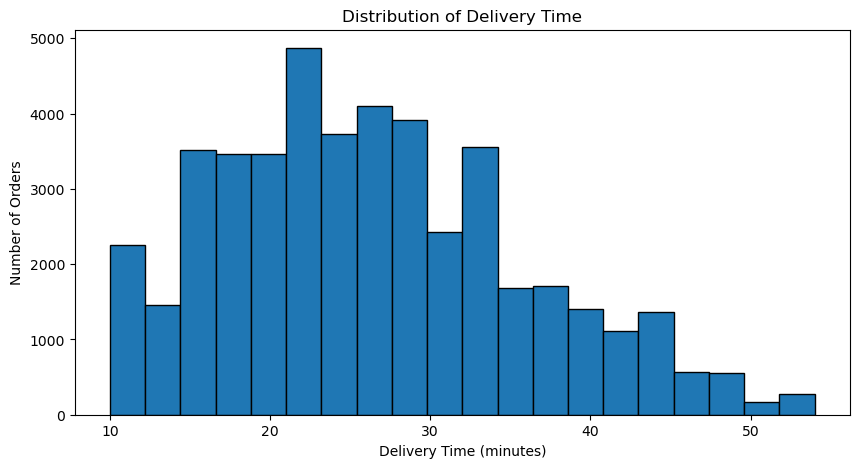

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(delivery_time, bins=20, edgecolor="black")

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of Orders")

plt.show()

In [28]:
print("متوسط وقت التوصيل:", delivery_time.mean())
print("الوسيط:", delivery_time.median())
print("أكثر وقت تكرارًا:", delivery_time.mode()[0])
print("أقل وقت:", delivery_time.min())
print("أعلى وقت:", delivery_time.max())

متوسط وقت التوصيل: 26.29460662821047
الوسيط: 26.0
أكثر وقت تكرارًا: 26
أقل وقت: 10
أعلى وقت: 54


**الاستنتاج:**

أظهرت النتائج أن متوسط وقت التوصيل يبلغ 26.29 دقيقة، والوسيط والمنوال يساويان 26 دقيقة. وتتراوح مدة التوصيل بين 10 و54 دقيقة.

يشير تقارب المتوسط والوسيط والمنوال إلى تمركز أوقات التوصيل حول 26 دقيقة، مع وجود اختلاف واضح في مدة وصول الطلبات، مما يستدعي دراسة العوامل المؤثرة في التأخير.

### 5.2 العلاقة بين الازدحام المروري ووقت التوصيل

أحلل العلاقة بين كثافة الازدحام المروري ووقت التوصيل لمعرفة ما إذا كانت الطلبات تستغرق وقتًا أطول في حالات الازدحام الشديد.

In [29]:
traffic_time = df.assign(
    Delivery_Time=delivery_time
).groupby("Road_traffic_density")["Delivery_Time"].mean()

print(traffic_time)

Road_traffic_density
High       27.240000
Jam        31.176624
Low        21.266977
Medium     26.699644
NaN        26.542429
Name: Delivery_Time, dtype: float64


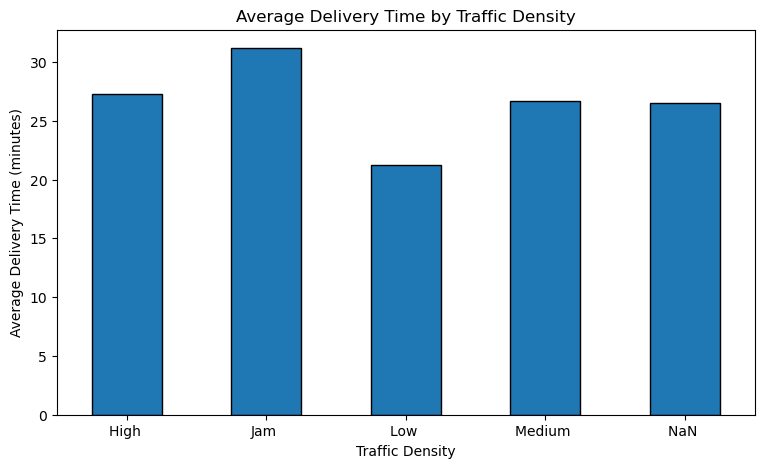

In [30]:
traffic_time.drop("NaN", errors="ignore").plot(
    kind="bar",
    figsize=(9, 5),
    edgecolor="black"
)

plt.title("Average Delivery Time by Traffic Density")
plt.xlabel("Traffic Density")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=0)
plt.show()

**الاستنتاج:**

أظهرت النتائج وجود علاقة بين مستوى الازدحام المروري ومتوسط وقت التوصيل. فقد بلغ متوسط التوصيل في الازدحام الشديد (Jam) حوالي 31.18 دقيقة، مقارنة بحوالي 21.27 دقيقة في الازدحام المنخفض (Low).

يشير ذلك إلى أن الطلبات أثناء الازدحام الشديد تستغرق وقتًا أطول في المتوسط، مما يجعل كثافة المرور عاملًا مهمًا يستحق أخذه في الاعتبار عند بناء نموذج التنبؤ بوقت التوصيل.  

### 5.3 العلاقة بين حالة الطقس ووقت التوصيل

أحلل العلاقة بين حالة الطقس ووقت التوصيل لمعرفة ما إذا كانت الظروف الجوية المختلفة مرتبطة باختلاف مدة وصول الطلبات.

In [31]:
weather_time = df.assign(
    Delivery_Time=delivery_time,
    Weather=df["Weatherconditions"].str.replace(
        "conditions ", "", regex=False
    ).str.strip()
).groupby("Weather")["Delivery_Time"].mean()

print(weather_time)

Weather
Cloudy        28.917330
Fog           28.916122
NaN           26.545455
Sandstorms    25.875517
Stormy        25.870815
Sunny         21.856947
Windy         26.118836
Name: Delivery_Time, dtype: float64


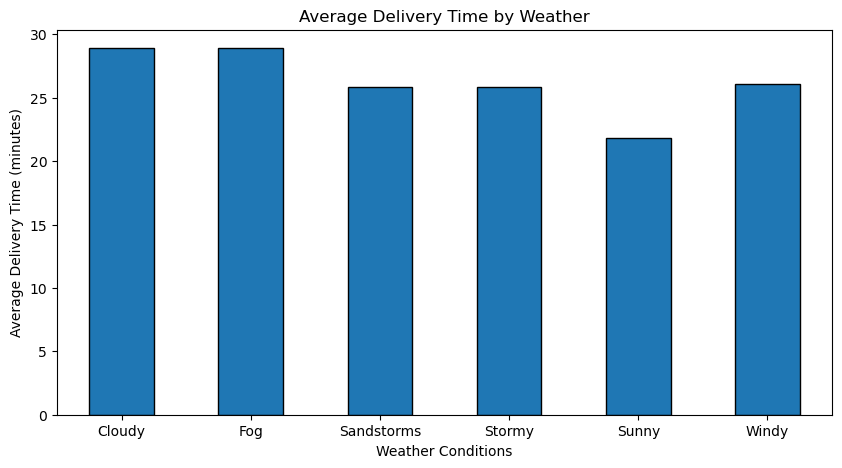

In [32]:
weather_time.drop("NaN", errors="ignore").plot(
    kind="bar",
    figsize=(10, 5),
    edgecolor="black"
)

plt.title("Average Delivery Time by Weather")
plt.xlabel("Weather Conditions")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=0)
plt.show()

**الاستنتاج:**

أظهرت النتائج اختلاف متوسط وقت التوصيل حسب حالة الطقس؛ فقد سجل الطقس الغائم أعلى متوسط بحوالي 28.92 دقيقة، يليه الضباب بحوالي 28.92 دقيقة، بينما سجل الطقس المشمس أقل متوسط بحوالي 21.86 دقيقة.

يوضح ذلك أن حالة الطقس قد تكون مرتبطة بمدة التوصيل، ولذلك من المهم تضمينها ضمن الخصائص المستخدمة في نموذج التنبؤ، مع مراعاة أن هذه النتائج توضح علاقة إحصائية ولا تثبت أن الطقس هو السبب المباشر للتأخير.   